<a href="https://colab.research.google.com/github/aishahifritcd24-star/DLG_lab/blob/main/Aishah_Ifrit_1BM24CD003.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models, layers

(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [2]:
PIXEL_MAX = 255.0

x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX

In [3]:
TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape(-1, TIME_STEPS, FEATURES)
x_test = x_test.reshape(-1, TIME_STEPS, FEATURES)

In [4]:
NUM_CLASSES = 10

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

In [5]:
RNN_UNITS = 128

model = models.Sequential()

model.add(layers.SimpleRNN(
    RNN_UNITS,
    activation='relu',
    input_shape=(TIME_STEPS, FEATURES)
))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
OUT_UNITS = 10

model.add(layers.Dense(
    OUT_UNITS,
    activation=None
))

In [7]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8286 - loss: 0.5340 - val_accuracy: 0.9310 - val_loss: 0.2475
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9399 - loss: 0.2042 - val_accuracy: 0.9517 - val_loss: 0.1621
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9542 - loss: 0.1544 - val_accuracy: 0.9577 - val_loss: 0.1463
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9618 - loss: 0.1276 - val_accuracy: 0.9606 - val_loss: 0.1344
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9635 - loss: 0.1225 - val_accuracy: 0.9658 - val_loss: 0.1128
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9685 - loss: 0.1057 - val_accuracy: 0.9672 - val_loss: 0.1120
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9710 - loss: 0.0976 - val_accuracy: 0.9693 - val_loss: 0.1024
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9727 - loss: 0.0922 - val_accuracy: 0

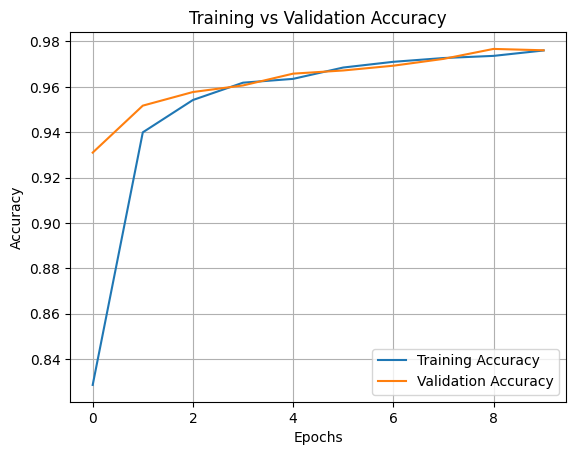

In [10]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()